# Custom triangle playground

This notebook is a compact playground for custom ternary plots built with the project plotting functions.

It is designed so the user can:
- define a custom dataframe directly in the notebook,
- generate fixed plots with different settings,
- compare views with and without trajectories,
- rotate the triangle,
- and use an interactive widget-based view to explore the same data quickly.

Important note: a ternary plot is meaningful as a simplex representation only when the three plotted coordinates are non-negative parts of the same whole. In practice, each row should already sum to a common constant, or should at least be interpretable after normalization as a decomposition of one shared quantity.

If the three columns are unrelated magnitudes, they can still be normalized and plotted, but the simplex geometry should then be read only as a visual embedding rather than as a true compositional balance.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpltern  # registers the ternary projection
from IPython.display import display

BASE_DIR = Path("..").resolve()
SRC_DIR = BASE_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

from visualize_triangles import plot_custom_triangle, plot_custom_triangle_interactive

## Example dataframe

The dataframe below is defined explicitly in the notebook so that the playground is self-contained and easy to edit.

The three simplex coordinates are:
- `sigma`
- `delta`
- `Delta`

They already satisfy the simplex condition row by row:
`sigma + delta + Delta = 1`.


In [2]:
custom_triangle_df = pd.DataFrame(
    {
        "sigma": [0.58, 0.46, 0.37, 0.28, 0.22, 0.18],
        "delta": [0.17, 0.24, 0.29, 0.34, 0.38, 0.40],
        "Delta": [0.25, 0.30, 0.34, 0.38, 0.40, 0.42],
        "step": [1, 2, 3, 4, 5, 6],
        "group": ["B1", "B2", "B3", "B4", "B5", "B6"],
    }
)

custom_triangle_df["simplex_sum"] = (
    custom_triangle_df["sigma"]
    + custom_triangle_df["delta"]
    + custom_triangle_df["Delta"]
)

display(custom_triangle_df)
# To save this table, use custom_triangle_df.to_csv(BASE_DIR / "results" / "custom_triangle_df.csv", index=False).

,sigma,delta,Delta,step,group,simplex_sum
0,0.58,0.17,0.25,1,B1,1.0
1,0.46,0.24,0.30,2,B2,1.0
2,0.37,0.29,0.34,3,B3,1.0
3,0.28,0.34,0.38,4,B4,1.0
4,0.22,0.38,0.40,5,B5,1.0
5,0.18,0.40,0.42,6,B6,1.0


## Plot configuration

Edit this cell to try different settings in the fixed plot.

Useful parameters to play with:
- `rotation`: rotate the simplex view. In practice, the clearest ternary orientations are usually `0`,`60`, `120`, `180`, etc.
- `normalize`: whether to normalize the three coordinates before plotting
- `show_trajectory`: toggle the trajectory overlay
- `trajectory_mode`: `"raw"` or `"centroid"`
- `accumulate`: show only one step or all points up to that step
- `marker_by`: use a categorical column to vary markers
- `color_by`: use a numeric column to color points


In [9]:
coord_cols = ("sigma", "delta", "Delta")
labels = (r"$\sigma$", r"$\delta$", r"$\Delta$")

rotation = 60
normalize = False

value_col = "step"
value = int(custom_triangle_df["step"].max())
accumulate = True

color_by = "step"
marker_by = None

show_trajectory = True
trajectory_mode = "raw"
trajectory_sort_by = "step"

fixed_title = "Custom triangle | fixed view"

display(custom_triangle_df[["step", "group", "sigma", "delta", "Delta", "simplex_sum"]])

,step,group,sigma,delta,Delta,simplex_sum
0,1,B1,0.58,0.17,0.25,1.0
1,2,B2,0.46,0.24,0.30,1.0
2,3,B3,0.37,0.29,0.34,1.0
3,4,B4,0.28,0.34,0.38,1.0
4,5,B5,0.22,0.38,0.40,1.0
5,6,B6,0.18,0.40,0.42,1.0


## Fixed plot

This cell uses the project function directly and is the best place to test a specific configuration for a figure that could later be saved.


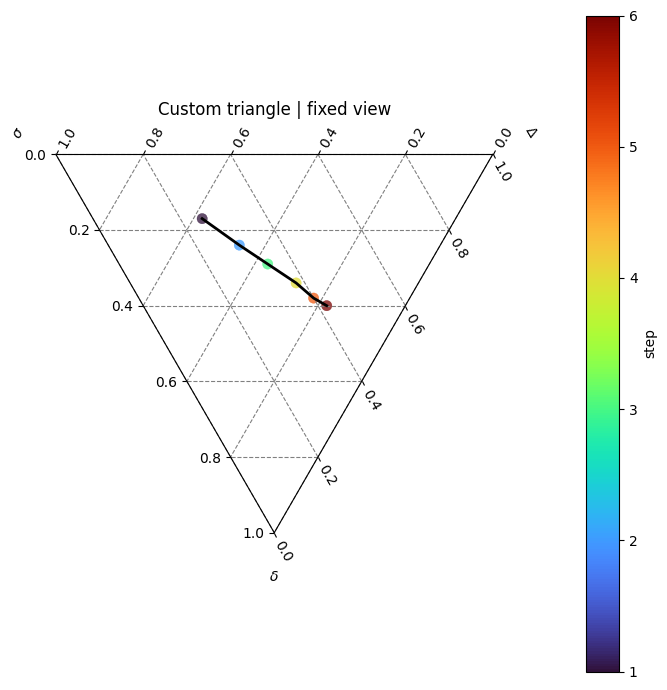

<Figure size 640x480 with 0 Axes>

In [7]:
plot_custom_triangle(
    df=custom_triangle_df,
    coord_cols=coord_cols,
    rotation=rotation,
    labels=labels,
    normalize=normalize,
    value_col=value_col,
    value=value,
    accumulate=accumulate,
    color_by=color_by,
    marker_by=marker_by,
    marker_legend=bool(marker_by),
    show_colorbar=True,
    s=55,
    alpha=0.75,
    title=fixed_title,
    ax=None,
    show_trajectory=show_trajectory,
    trajectory_mode=trajectory_mode,
    trajectory_sort_by=trajectory_sort_by,
)

plt.tight_layout()
plt.show()
# To save this figure, use plt.gcf().savefig(BASE_DIR / "figures" / "custom_triangle_fixed.png", dpi=300, bbox_inches="tight").

## Interactive playground

This widget-based view is useful for quick exploration. It lets the user move through the selected `slider_col` and compare exact-step views against accumulated trajectories.


In [8]:
plot_custom_triangle_interactive(
    df=custom_triangle_df,
    coord_cols=coord_cols,
    rotation=0,
    slider_col="step",
    slider_values=sorted(custom_triangle_df["step"].unique()),
    labels=labels,
    normalize=False,
    accumulate_default=True,
    color_by="step",
    show_trajectory=True,
    trajectory_mode="raw",
    trajectory_sort_by="step",
    s=55,
    alpha=0.75,
    title="Interactive custom triangle playground",
)
# To save one view from this widget, reproduce the same parameters in a fixed plotting cell and save the resulting figure in BASE_DIR / "figures". 

interactive(children=(IntSlider(value=0, description='step idx', max=5), Checkbox(value=True, description='Acc…

## Adapting the playground

To reuse this notebook with your own data, only three things are strictly necessary:

1. Replace `custom_triangle_df` with your own dataframe.
2. Update `coord_cols` so they point to the three simplex coordinates.
3. Decide whether the coordinates should be used as they are or normalized before plotting.

Everything else in the notebook is there only to make experimentation easier.
